<a href="https://colab.research.google.com/github/infinityrohit07/tensorflow-learning/blob/main/notebooks/13_training_validation_testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Understanding Dataset Seperation**

In practice, we often divide our dataset into three parts:

1. **Training data**
2. **Validation data**
3. **Testing data**

An example split:

- Training data → 70%
- Validation data → 15%
- Testing data → 15%

These percentages can vary depending on the dataset and problem.

<br>

#### 1. **Training Data**

Used to teach the model by updating its weights and biases.

<br>

#### 2. **Validation Data**

Used to monitor the model's performance during training and help make decisions, such as:

- Adjusting the learning rate.
- Changing the number of epochs.
- Selecting model architecture.
- Identifying overfitting.

<br>

#### 3. **Testing Data**

Used for the final evaluation after model development is complete.

<br>

**Remember:**

- Training data → Teaches the model.
- Validation data → Helps us make development decisions.
- Testing data → Provides an independent final performance check.

### **Understanding splitting of dataset**

#### **Why do we split the dataset?**

If we evaluate a model using only the data it learned from, we might get good results even if it performs poorly on new data.

Testing data helps us determine whether the model can generalize to unseen examples.

<br>

#### **Random Splitting**

We generally shuffle the dataset before splitting it into training and testing data.

This helps prevent situations where one part of the dataset contains only certain types of examples.

**Important:** Input features and their corresponding labels must remain paired when shuffling and splitting.

### **The three important terms - Overfitting, Underfitting, and Generalisation**

#### 1. **Overfitting**

Overfitting happens when a model learns the training data too closely, including noise or patterns that do not generalize well to unseen data.

<br>

#### 2. **Underfitting**

Underfitting happens when a model fails to learn the underlying patterns in the training data.

<br>

#### 3. **Generalization**

Generalization is the ability of a model to perform well on data it hasn't seen during training.

A good model should learn meaningful patterns from training data and apply them to unseen data.

<br>

#### **Overfitting vs Underfitting**

| Overfitting | Underfitting |
|---|---|
| Learns training data too closely | Fails to learn patterns properly |
| Training performance is good | Training performance is poor |
| Validation performance is poor | Validation performance is poor |
| Struggles to generalize | Has not learned enough |

### **Loss Curves**

In this section, you don't have to understand the matplotlib code. Just watch the curves and understand what happens in each of these with training loss and validation loss as given.

In [ ]:
import matplotlib.pyplot as plt

#### 1. **Example of Underfitting using Loss Curves**

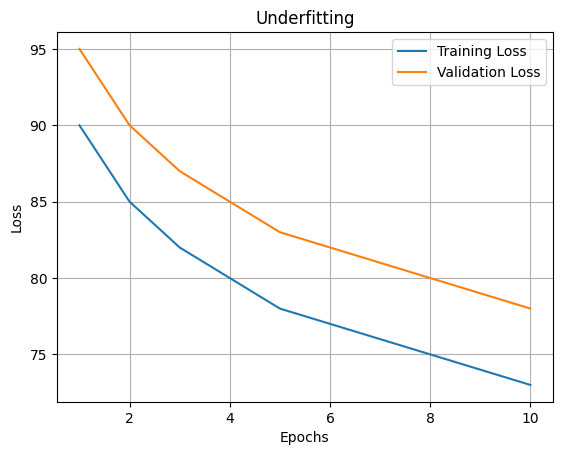

In [ ]:
epochs = range(1, 11)

training_loss = [90, 85, 82, 80, 78, 77, 76, 75, 74, 73]
validation_loss = [95, 90, 87, 85, 83, 82, 81, 80, 79, 78]

plt.plot(epochs, training_loss, label="Training Loss")
plt.plot(epochs, validation_loss, label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Underfitting")

plt.legend()
plt.grid()
plt.show()

Here in underfitting:

- Training loss is high.

- Validation loss is also high.

- The model hasn't learned the underlying patterns properly.

#### 2. **Example of Good Fit using Loss Curves**

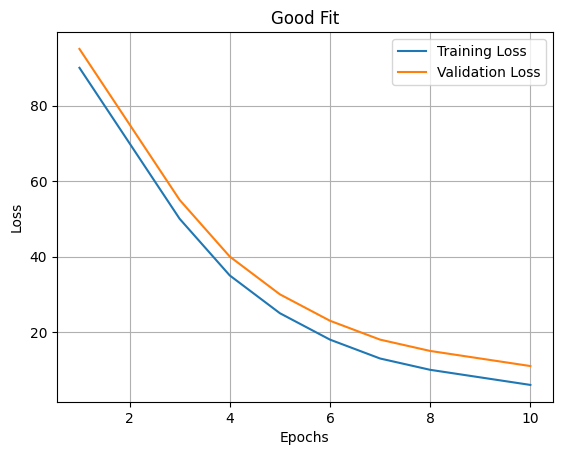

In [ ]:
epochs = range(1, 11)

training_loss = [90, 70, 50, 35, 25, 18, 13, 10, 8, 6]
validation_loss = [95, 75, 55, 40, 30, 23, 18, 15, 13, 11]

plt.plot(epochs, training_loss, label="Training Loss")
plt.plot(epochs, validation_loss, label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Good Fit")

plt.legend()
plt.grid()
plt.show()

In Good Fit:

- Training loss is low.

- Validation loss is also low.

- Both losses decrease and remain reasonably close.

The model generalizes well.

#### 3. **Example of Overfitting using Loss Curves**

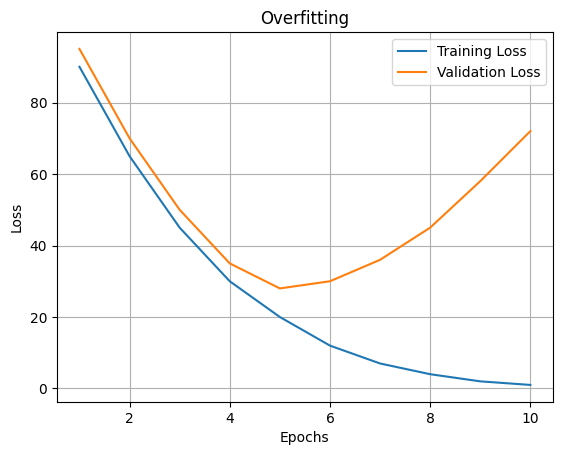

In [ ]:
epochs = range(1, 11)

training_loss = [90, 65, 45, 30, 20, 12, 7, 4, 2, 1]
validation_loss = [95, 70, 50, 35, 28, 30, 36, 45, 58, 72]

plt.plot(epochs, training_loss, label="Training Loss")
plt.plot(epochs, validation_loss, label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Overfitting")

plt.legend()
plt.grid()
plt.show()

In Overfitting:

- Training loss continues decreasing.

- Validation loss starts increasing.

- The model is learning the training data too closely and struggling with unseen data.

### **Preventing Overfitting and Underfitting**

Overfitting and underfitting are two common problems in machine learning. We use different techniques to help a model learn patterns effectively and generalize well to unseen data.

<br>

#### **1. Preventing Overfitting**

Overfitting occurs when a model learns the training data too closely, including noise and unnecessary details. As a result, it performs well on training data but poorly on unseen data.

<br>

##### **Techniques to Prevent Overfitting**

<br>

**1. Early Stopping**

Early stopping stops model training when validation performance stops improving.

- It monitors validation loss (`val_loss`).
- If validation loss stops decreasing for a specified number of epochs, training stops.
- It prevents the model from continuing to train and potentially overfitting.
- `restore_best_weights=True` restores the weights from the epoch with the best validation performance.

Example:

```python
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)
```

<br>

**2. Dropout**

Dropout is a regularization technique that randomly switches off a percentage of neurons during training.

- It prevents the network from becoming too dependent on particular neurons.
- It encourages the network to learn more robust patterns.
- The dropout rate determines the percentage of neurons temporarily switched off.
- Dropout is active during training but disabled during normal prediction (inference).

Example:

```python
tf.keras.layers.Dropout(0.3)
```

A dropout rate of `0.3` means approximately 30% of the neurons are temporarily switched off during each training batch.

<br>

**3. Reduce Model Complexity**

A model that is unnecessarily complex may learn noise and specific details from the training data.

We can reduce complexity by:
- Reducing the number of layers.
- Reducing the number of neurons.
- Using a simpler model architecture.

<br>

**4. Get More Training Data**

More diverse training examples can help the model learn general patterns instead of memorizing a limited dataset.

<br>
<br>

#### **2. Preventing Underfitting**

Underfitting occurs when a model fails to learn the underlying patterns in the training data.

As a result, it performs poorly on both training and validation data.

<br>

##### **Techniques to Prevent Underfitting**

<br>

**1. Increase Model Complexity**

A model may be too simple to learn complex patterns.

We can increase its learning capacity by:
- Increasing the number of neurons.
- Adding more layers.
- Choosing a more suitable architecture.

<br>

**2. Train for More Epochs**

Sometimes the model has not received enough training to learn the underlying patterns.

Increasing the number of epochs gives the model more opportunities to learn from the training data.

<br>

**3. Improve Input Features**

Providing more useful and relevant input features can help the model identify patterns more effectively.

<br>

**4. Reduce Excessive Regularization**

Regularization techniques such as Dropout prevent overfitting. However, applying too much regularization can make it difficult for the model to learn.

Reducing excessive regularization can help improve model learning.

<br>

#### **Comparison**

| Technique | Helps Prevent |
|---|---|
| Early Stopping | Overfitting |
| Dropout | Overfitting |
| Reduce Model Complexity | Overfitting |
| Get More Training Data | Overfitting |
| Increase Model Complexity | Underfitting |
| Train for More Epochs | Underfitting |
| Improve Input Features | Underfitting |
| Reduce Excessive Regularization | Underfitting |

<br>

**Remember:** The goal is not simply to achieve high training accuracy. The goal is to build a model that generalizes well to new, unseen data.

### **Bias-Variance Tradeoff**

The bias-variance tradeoff describes the balance between two types of errors that affect a machine learning model's ability to generalize.

<br>

#### A. Bias

Bias is the error caused by a model making overly simple assumptions about the data.

A model with high bias:
- Is too simple to learn important patterns.
- Performs poorly on training data.
- Usually leads to underfitting.

<br>

#### B. Variance

Variance refers to how sensitive a model is to changes in its training data.

A model with high variance:
- Learns training data too closely.
- May learn noise instead of general patterns.
- Performs well on training data but poorly on unseen data.
- Usually leads to overfitting.

<br>

#### **Comparison**

| High Bias | High Variance |
|---|---|
| Model is too simple | Model is too sensitive to training data |
| Underfitting | Overfitting |
| Poor training performance | Good training performance |
| Poor validation performance | Poor validation performance |


<br>

**Important observations:**

- High training loss and high validation loss generally indicate high bias.
- Low training loss but high validation loss generally indicate high variance.
- The goal is to balance bias and variance so that the model generalizes well to unseen data.

### **Parameters vs Hyperparameters**

##### 1. **Parameters**

Parameters are values that a model learns automatically during training.

Examples:
- Weights
- Biases

The optimizer updates these values to reduce the loss.

<br>

##### 2. **Hyperparameters**

Hyperparameters are settings that we choose to control the model architecture and training process.

Examples:
- Learning rate
- Number of epochs
- Batch size
- Number of layers
- Number of neurons per layer
- Dropout rate

<br>

##### **Comparison**

| Parameters | Hyperparameters |
|---|---|
| Learned during training | Chosen by us |
| Weights and biases | Learning rate and batch size |
| Updated by the optimizer | Adjusted through experimentation |

<br>
<br>

#### **Hyperparameter Tuning**

Hyperparameter tuning is the process of experimenting with different hyperparameter values to find a configuration that gives the best validation performance.

For example, we can experiment with different learning rates:

| Experiment | Learning Rate | Validation Loss |
|---|---:|---:|
| 1 | 0.1 | 15.2 |
| 2 | 0.01 | 5.8 |
| 3 | 0.001 | 9.4 |

In this example, a learning rate of `0.01` gives the lowest validation loss.

Therefore, it is the best choice among these three experiments.

<br>

**Important points:**
- We use validation data to tune hyperparameters.
- We can experiment with learning rates, batch sizes, epochs, model complexity and dropout rates.
- We should not repeatedly use test data to make tuning decisions.
- The best configuration is selected based on validation performance.

### **Complete Model Development Workflow**

A machine learning model follows a series of steps from data preparation to deployment.

Step 1: Collect and Prepare Data
- Gather the dataset.
- Clean and preprocess the data.
- Separate input features (`X`) and labels (`y`).

Step 2: Split the Dataset
Divide the dataset into:
- Training data
- Validation data
- Testing data

Step 3: Build the Model
Choose:
- Model architecture
- Number of layers
- Number of neurons
- Activation functions

Step 4: Train the Model
- Use training data to teach the model.
- The model learns weights and biases.
- The optimizer updates these parameters to reduce loss.

Step 5: Monitor Validation Performance
- Monitor validation loss and metrics.
- Identify overfitting and underfitting.
- Check how well the model generalizes.

Step 6: Tune Hyperparameters
Experiment with:
- Learning rate
- Batch size
- Number of epochs
- Model complexity
- Regularization techniques

Step 7: Select the Best Model
Choose the model configuration that performs well on validation data.

Step 8: Evaluate Using Test Data
- Perform the final evaluation using the untouched test dataset.
- Check how well the model performs on unseen data.

Step 9: Deploy the Model
Use the trained model to make predictions on new real-world data.

### Data Leakage

Data leakage occurs when information from outside the training data improperly influences the model during training or model development.

It can make a model appear to perform very well during evaluation, even though it may perform poorly on genuinely unseen data.

<br>

#### Example

Suppose we have 1,000 samples:
- 800 training samples
- 200 testing samples

Before splitting the dataset, we calculate the mean and standard deviation using all 1,000 samples.

This allows information from the test dataset to influence the preprocessing process.

This is a form of data leakage.

<br>

#### Correct Approach

1. Split the dataset first.
2. Calculate preprocessing statistics (such as mean and standard deviation) using training data only.
3. Use those same statistics to transform validation and testing data.

Example:

```python
# Calculate statistics using training data only
mean = X_train.mean()
std = X_train.std()

# Apply the same statistics to all datasets
X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std
```

**Important:**
- Training data → Fit preprocessing.
- Validation data → Transform using training statistics.
- Testing data → Transform using training statistics.

We do not calculate separate means and standard deviations for validation and testing data.

This ensures that information from validation and test datasets does not leak into the training process.